<a href="https://colab.research.google.com/github/dzakki08/Studi_Kasus_Attributing_direct_drivers_to_deforestation_alerts_with_satellite_imagery_and_AI.ipynb/blob/main/Studi_Kasus_Final_AI_Citra_Satelit_Pemantauan_Mangrove.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studi Kasus Lengkap: Pemanfaatan AI dan Citra Satelit untuk Pemantauan Perubahan Ekosistem Mangrove Pesisir
### Informatics Practitioner Lecture Series 2026

**Narasumber:** Dr. Bart Slachter, peneliti dari Wageningen University.

Notebook ini mengembangkan resume materi menjadi contoh alur kerja pembelajaran mengenai pemantauan perubahan ekosistem mangrove menggunakan citra satelit, pengolahan fitur, klasifikasi, evaluasi, dan interpretasi hasil.

> **Batas sumber:** penjelasan narasumber dalam resume menjadi dasar konteks studi kasus. Kode di notebook ini merupakan demonstrasi edukatif dengan data sintetis, bukan reproduksi model penelitian asli, bukan implementasi resmi Global Nature Watch, dan bukan hasil pengamatan perubahan mangrove nyata.

## 1. Latar Belakang

Ekosistem mangrove pesisir membantu melindungi garis pantai, menyimpan karbon, menyediakan habitat bagi berbagai organisme, dan mendukung kehidupan masyarakat pesisir. Ekosistem ini dapat mengalami perubahan akibat pembukaan tambak, pembangunan kawasan pesisir, abrasi, maupun faktor alami. Pemantauan wilayah yang luas secara berkala dapat dibantu oleh citra satelit dan metode kecerdasan buatan (AI).

Citra satelit bukan bukti tunggal untuk memastikan penyebab perubahan. Informasi hasil klasifikasi perlu dibandingkan dengan data rujukan, pengamatan lapangan, dan konteks setempat.

## 2. Rumusan Masalah

1. Mengapa pemantauan mangrove membutuhkan data satelit yang konsisten?
2. Apa perbedaan informasi dari Sentinel-1 dan Sentinel-2?
3. Bagaimana model klasifikasi dapat membantu mengelompokkan indikasi perubahan ekosistem mangrove?
4. Bagaimana mengevaluasi hasil model dan menghindari kesimpulan yang berlebihan?
5. Mengapa validasi lapangan tetap diperlukan?

## 3. Tujuan

- Memahami peran citra satelit dalam pemantauan ekosistem mangrove pesisir.
- Mengenali perbedaan citra radar Sentinel-1 dan citra optik Sentinel-2.
- Memahami konsep CNN untuk klasifikasi citra.
- Menyimulasikan alur klasifikasi dengan fitur numerik sintetis dan Random Forest.
- Mengevaluasi hasil klasifikasi serta memahami keterbatasannya.

## 4. Dasar Teori

### 4.1 Sentinel-1
Sentinel-1 menggunakan radar sehingga pengamatan lebih konsisten pada kondisi berawan. Sinyal radar memberikan informasi mengenai karakteristik permukaan dan struktur vegetasi, tetapi interpretasinya berbeda dari citra optik.

### 4.2 Sentinel-2
Sentinel-2 menggunakan sensor optik yang merekam pantulan pada beberapa kanal spektral. Data ini dapat membantu mempelajari kondisi vegetasi, tetapi kualitas pengamatan dapat terganggu oleh awan dan bayangan.

### 4.3 Penggabungan data
Menggabungkan fitur radar dan optik dapat memberikan informasi yang saling melengkapi. Namun, data perlu disejajarkan secara spasial dan temporal, diperiksa kualitasnya, serta ditangani bila terdapat nilai hilang atau awan.

### 4.4 CNN
Convolutional Neural Network (CNN) merupakan jenis Deep Learning yang dapat mempelajari pola spasial dari citra melalui operasi konvolusi. CNN biasanya membutuhkan data berlabel yang cukup, pengaturan pelatihan yang tepat, dan evaluasi pada wilayah atau waktu yang tidak digunakan saat training.

## 5. Kelas Contoh Perubahan Ekosistem Mangrove

Untuk demonstrasi ini, kelas yang digunakan adalah kategori indikatif berikut:

- Pembukaan tambak.
- Perluasan tambak.
- Pembangunan kawasan pesisir.
- Pengambilan kayu mangrove.
- Abrasi pantai.
- Kerusakan vegetasi.
- Variasi alami.

Kelas ini hanya label simulasi. Pada penelitian nyata, definisi kelas harus disusun dengan ahli lokal dan label rujukan yang dapat diverifikasi.

## 6. Rancangan Alur Kerja

1. **Menentukan wilayah dan periode:** tetapkan batas kawasan serta waktu pengamatan.
2. **Mengumpulkan data:** memperoleh citra Sentinel-1, Sentinel-2, dan label rujukan yang dapat diverifikasi.
3. **Prapemrosesan:** menangani awan pada citra optik, memeriksa kualitas radar, menyelaraskan resolusi dan proyeksi, serta menyamakan periode.
4. **Membangun sampel:** memotong citra menjadi patch dan menghubungkannya dengan label yang tervalidasi.
5. **Membagi data:** pisahkan data training, validation, dan testing berdasarkan lokasi atau waktu untuk mengurangi kebocoran spasial.
6. **Melatih model:** gunakan CNN atau model pembanding yang sesuai.
7. **Mengevaluasi:** periksa confusion matrix, precision, recall, F1-score per kelas, serta performa antarwilayah.
8. **Memvalidasi lapangan:** bandingkan hasil klasifikasi dengan bukti lapangan atau interpretasi ahli.
9. **Menyajikan hasil:** petakan prediksi dengan keterangan ketidakpastian dan tanggal data.

## 7. Data dan Fitur yang Diperlukan

Contoh fitur yang mungkin digunakan dalam proyek nyata:
- Kanal optik Sentinel-2, seperti kanal merah, hijau, biru, inframerah dekat, dan inframerah gelombang pendek.
- Fitur radar Sentinel-1, seperti polarisasi VV dan VH bila tersedia pada produk yang digunakan.
- Indeks vegetasi yang dihitung dari kanal optik setelah prapemrosesan yang sesuai.
- Informasi waktu, lokasi, tutupan lahan sebelumnya, dan label rujukan.

Pilihan fitur bergantung pada pertanyaan penelitian, karakteristik wilayah, ketersediaan data, dan metode prapemrosesan. Notebook ini tidak mengunduh atau mengolah citra satelit asli.

## 8. Demonstrasi Edukatif dengan Data Sintetis

Agar alur evaluasi dapat dicoba tanpa mengunduh citra satelit, bagian berikut membuat dataset fitur numerik sintetis untuk mengilustrasikan klasifikasi indikasi perubahan ekosistem mangrove. Data ini bukan piksel Sentinel, bukan hasil pengukuran lapangan, dan tidak dapat digunakan untuk menyimpulkan kondisi mangrove yang sebenarnya.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 9. Membuat Dataset Simulasi

In [ ]:
classes = [
    "Pembukaan tambak",
    "Perluasan tambak",
    "Pembangunan pesisir",
    "Pengambilan kayu mangrove",
    "Abrasi pantai",
    "Kerusakan vegetasi",
    "Variasi alami"
]

n_per_class = 120
rows = []

# Fitur-fitur sintetis untuk ilustrasi, bukan band atau indeks satelit yang sebenarnya.
for class_id, label in enumerate(classes):
    rows.append
    for _ in range(n_per_class):
        rows.append({
            "optical_vegetation_index": np.clip(rng.normal([0.38, 0.30, 0.34, 0.48, 0.28, 0.22, 0.55][class_id], 0.12), -1, 1),
            "radar_change_index": rng.normal([0.48, 0.58, 0.72, 0.52, 0.78, 0.70, 0.30][class_id], 0.20),
            "bare_soil_index": np.clip(rng.normal([0.62, 0.68, 0.75, 0.35, 0.72, 0.60, 0.28][class_id], 0.18), -1, 1),
            "texture_change_index": rng.normal([0.45, 0.55, 0.80, 0.58, 0.75, 0.65, 0.32][class_id], 0.22),
            "change_type": label
        })

df = pd.DataFrame(rows)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
df.head()

,optical_vegetation_index,radar_change_index,bare_soil_index,texture_change_index,change_type
0,0.400541,0.567786,0.690195,0.884515,Kerusakan vegetasi
1,0.491145,0.379029,-0.214898,0.311436,Variasi alami
2,0.257180,0.515855,0.659599,0.749021,Pembukaan tambak
3,0.226971,0.743340,0.604043,0.879515,Abrasi pantai
4,0.187847,0.321173,0.699135,0.565321,Pembukaan tambak


## 10. Pemeriksaan Data

Periksa jumlah baris, tipe data, nilai kosong, distribusi kelas, dan statistik ringkas. Pada proyek nyata, pemeriksaan ini juga harus mencakup validitas koordinat, tanggal citra, tutupan awan, kualitas radar, dan konsistensi label.

In [ ]:
print("Ukuran data:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nNilai kosong:")
print(df.isna().sum())
print("\nDistribusi kelas:")
print(df["change_type"].value_counts())
display(df.describe())

Ukuran data: (840, 5)

Tipe data:
optical_vegetation_index    float64
radar_change_index          float64
bare_soil_index             float64
texture_change_index        float64
change_type                  object
dtype: object

Nilai kosong:
optical_vegetation_index    0
radar_change_index          0
bare_soil_index             0
texture_change_index        0
change_type                 0
dtype: int64

Distribusi kelas:
change_type
Kerusakan vegetasi           120
Variasi alami                120
Pembukaan tambak             120
Abrasi pantai                120
Pembangunan pesisir          120
Pengambilan kayu mangrove    120
Perluasan tambak             120
Name: count, dtype: int64


,optical_vegetation_index,radar_change_index,bare_soil_index,texture_change_index
count,840.000000,840.000000,840.000000,840.000000
mean,0.361278,0.579188,0.564775,0.582804
std,0.158849,0.251592,0.245406,0.271401
min,-0.064663,-0.203219,-0.214898,-0.282697
25%,0.251663,0.403009,0.395132,0.405670
50%,0.354577,0.591861,0.583975,0.573430
75%,0.465357,0.757793,0.746084,0.768790
max,0.920621,1.351488,1.000000,1.323097


### Visualisasi distribusi kelas

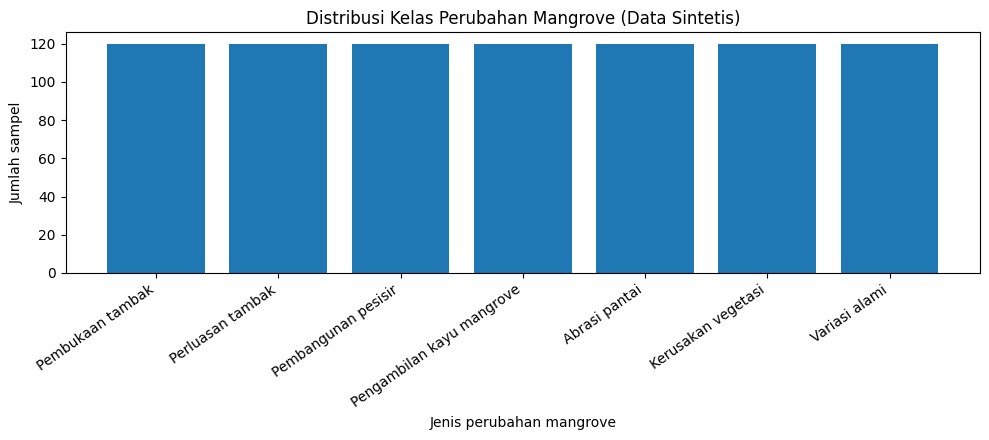

In [ ]:
class_counts = df["change_type"].value_counts().reindex(classes)
plt.figure(figsize=(10, 4.5))
plt.bar(class_counts.index, class_counts.values)
plt.title("Distribusi Kelas Perubahan Mangrove (Data Sintetis)")
plt.xlabel("Jenis perubahan mangrove")
plt.ylabel("Jumlah sampel")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 11. Membagi Data Training dan Testing

Data dipisahkan agar evaluasi dilakukan pada sampel yang tidak digunakan untuk pelatihan. Pada contoh sintetis, pembagian acak digunakan demi kesederhanaan. Untuk citra satelit nyata, pembagian acak per patch dapat menimbulkan kebocoran spasial karena patch berdekatan bisa sangat mirip. Karena itu, evaluasi yang lebih realistis memisahkan wilayah atau periode waktu.

In [ ]:
feature_cols = [
    "optical_vegetation_index",
    "radar_change_index",
    "bare_soil_index",
    "texture_change_index"
]
X = df[feature_cols]
y = df["change_type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (630, 4)
Testing : (210, 4)


## 12. Melatih Model Baseline

Random Forest digunakan sebagai model pembanding sederhana karena dapat menangani hubungan nonlinier pada fitur tabular. Ini bukan CNN dan tidak mempelajari struktur spasial langsung dari citra. Jika tujuan proyek adalah klasifikasi citra patch, CNN dapat digunakan pada tensor citra dengan pipeline dan evaluasi yang sesuai.

In [ ]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Akurasi:", round(accuracy_score(y_test, y_pred), 3))

Akurasi: 0.419


## 13. Evaluasi Klasifikasi

Accuracy memberikan gambaran keseluruhan, tetapi tidak cukup untuk menilai semua kelas. Precision menunjukkan ketepatan prediksi suatu kelas, sedangkan recall menunjukkan proporsi sampel kelas tersebut yang berhasil ditemukan. F1-score menggabungkan precision dan recall. Perhatikan metrik per kelas, khususnya kelas yang sulit dibedakan.

                           precision    recall  f1-score   support

            Abrasi pantai       0.41      0.37      0.39        30
       Kerusakan vegetasi       0.40      0.20      0.27        30
      Pembangunan pesisir       0.39      0.43      0.41        30
         Pembukaan tambak       0.33      0.43      0.38        30
Pengambilan kayu mangrove       0.54      0.50      0.52        30
         Perluasan tambak       0.24      0.30      0.26        30
            Variasi alami       0.70      0.70      0.70        30

                 accuracy                           0.42       210
                macro avg       0.43      0.42      0.42       210
             weighted avg       0.43      0.42      0.42       210



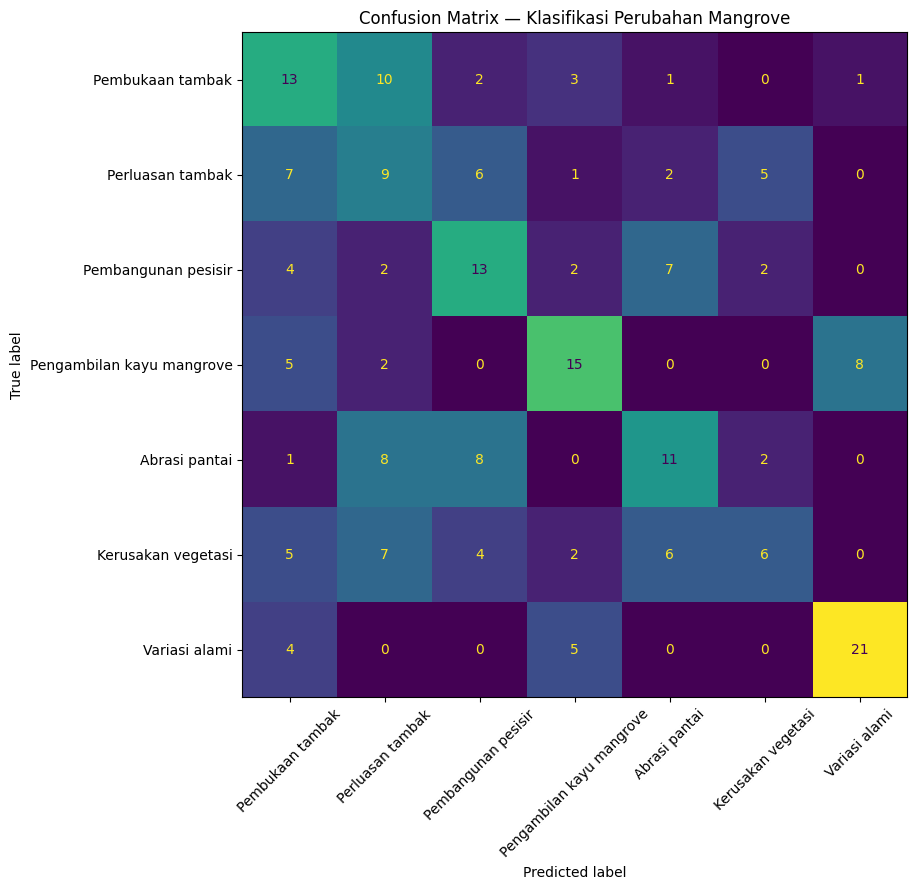

In [ ]:
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Confusion Matrix — Klasifikasi Perubahan Mangrove")
plt.tight_layout()
plt.show()

**Cara membaca confusion matrix:** nilai diagonal menunjukkan prediksi yang benar. Nilai di luar diagonal menunjukkan kelas yang tertukar. Jika dua jenis gangguan sering tertukar, hal itu menandakan fitur atau label belum cukup membedakan keduanya. Dalam konteks resume, pembedaan kebakaran dan gangguan alami merupakan salah satu tantangan yang disebutkan, tetapi hasil demonstrasi sintetis ini tidak menguji klaim penelitian tersebut.

## 14. Prediksi Satu Sampel Baru

Contoh berikut hanya menunjukkan format inferensi pada fitur sintetis. Nilai yang dimasukkan bukan hasil pengukuran satelit.

In [ ]:
sample = pd.DataFrame([{
    "optical_vegetation_index": 0.30,
    "radar_change_index": 0.76,
    "bare_soil_index": 0.70,
    "texture_change_index": 0.74
}])

predicted_class = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]
print("Prediksi kelas perubahan (sintetis):", predicted_class)

prob_table = pd.DataFrame({
    "kelas": model.classes_,
    "probabilitas_model": probabilities
}).sort_values("probabilitas_model", ascending=False)
display(prob_table)

Prediksi kelas perubahan (sintetis): Abrasi pantai


,kelas,probabilitas_model
0,Abrasi pantai,0.400
2,Pembangunan pesisir,0.300
5,Perluasan tambak,0.215
1,Kerusakan vegetasi,0.045
3,Pembukaan tambak,0.030
4,Pengambilan kayu mangrove,0.010
6,Variasi alami,0.000


## 15. CNN dan Model Pembanding

CNN dapat mempelajari pola spasial dari patch citra, sedangkan model tabular seperti Random Forest menggunakan fitur yang sudah diringkas. Perbandingan yang adil perlu memakai data, pembagian train-test, dan metrik evaluasi yang setara.

Pertimbangkan:
- Apakah CNN benar-benar meningkatkan performa dibandingkan baseline?
- Berapa banyak label terverifikasi yang diperlukan?
- Berapa waktu pelatihan dan kebutuhan komputasinya?
- Apakah peningkatan performa konsisten di wilayah dan waktu berbeda?
- Apakah kesalahan model berdampak besar pada keputusan konservasi?

Jangan menyimpulkan CNN selalu lebih baik hanya karena termasuk Deep Learning.

## 16. Tantangan dan Sumber Kesalahan

- **Awan dan bayangan:** dapat mengurangi kualitas pengamatan optik.
- **Keselarasan data:** citra radar dan optik perlu cocok dalam lokasi, resolusi, dan waktu.
- **Kelas yang mirip:** pola kebakaran, banjir, pembukaan lahan, dan gangguan lain dapat tumpang tindih.
- **Label yang tidak konsisten:** label salah atau definisi kelas yang tidak jelas akan mengganggu pelatihan.
- **Ketidakseimbangan kelas:** beberapa penyebab mungkin jauh lebih jarang dibanding yang lain.
- **Kebocoran spasial:** sampel yang berdekatan dapat membuat hasil uji tampak terlalu optimistis.
- **Perubahan wilayah:** model yang dilatih di satu wilayah mungkin tidak bekerja sama baiknya di wilayah lain.
- **Keterbatasan pembaruan:** interval pembaruan dan ketersediaan citra memengaruhi waktu deteksi.

## 17. Validasi Lapangan dan Interpretasi

Hasil klasifikasi perlu diperiksa melalui data lapangan, citra resolusi lebih tinggi bila tersedia, catatan otoritatif, atau interpretasi ahli. Validasi perlu mencakup sampel dari berbagai kelas dan wilayah, bukan hanya lokasi yang mudah dijangkau.

Peta prediksi sebaiknya menunjukkan tanggal data, kelas hasil, tingkat keyakinan bila tersedia, dan batasan interpretasi. Klasifikasi AI adalah indikasi untuk pemeriksaan lebih lanjut, bukan bukti otomatis terjadinya pelanggaran atau penyebab pasti perubahan ekosistem mangrove.

## 18. Transparansi, Kebijakan, dan Etika

Pemantauan satelit dapat membantu transparansi dan mendukung prioritas pemeriksaan. Namun:
- Hindari menuduh pelaku atau menetapkan penyebab pasti hanya dari prediksi model.
- Jelaskan sumber data, metode, waktu pengamatan, dan ketidakpastian.
- Lindungi informasi sensitif yang dapat membahayakan masyarakat atau kawasan tertentu.
- Pastikan hasil digunakan bersama verifikasi yang layak dan proses kebijakan yang adil.
- Dokumentasikan kesalahan model, terutama jika hasil memengaruhi keputusan penegakan hukum atau pengelolaan lahan.

## 19. Pertanyaan Diskusi

1. Apa perbedaan utama Sentinel-1 dan Sentinel-2?
2. Mengapa menggabungkan radar dan citra optik dapat bermanfaat?
3. Mengapa klasifikasi penyebab perubahan ekosistem mangrove lebih sulit daripada sekadar mendeteksi perubahan tutupan?
4. Apa fungsi CNN dalam klasifikasi citra?
5. Mengapa model perlu dibandingkan dengan metode yang lebih sederhana?
6. Apa arti precision, recall, dan F1-score dalam kasus ini?
7. Mengapa pemisahan data berdasarkan lokasi atau waktu penting?
8. Mengapa validasi lapangan tetap diperlukan?
9. Bagaimana hasil prediksi dapat membantu kebijakan tanpa menjadi satu-satunya dasar keputusan?

## 20. Keterbatasan Notebook

- Notebook menggunakan fitur dan label sintetis, bukan citra Sentinel-1 atau Sentinel-2 asli.
- Model yang dilatih adalah Random Forest pada fitur tabular, bukan CNN.
- Hasil evaluasi hanya menunjukkan perilaku model pada data buatan.
- Notebook tidak mereproduksi penelitian Dr. Bart Slachter dan tidak terhubung dengan Global Nature Watch.
- Tidak ada klaim angka akurasi penelitian asli yang dihitung atau diverifikasi di sini.

Untuk penelitian nyata, diperlukan data citra yang dapat ditelusuri, label rujukan terverifikasi, prapemrosesan geospasial yang benar, evaluasi lintas lokasi/waktu, dan validasi lapangan.

## 21. Kesimpulan

Citra satelit dan AI dapat mendukung pemantauan perubahan ekosistem mangrove pesisir pada wilayah luas. Sentinel-1 dan Sentinel-2 memberikan informasi yang saling melengkapi, sedangkan model klasifikasi dapat membantu mengelompokkan pola awal untuk ditinjau lebih lanjut. Notebook ini menggunakan fitur sintetis dan Random Forest tabular, bukan citra satelit asli atau CNN. Oleh sebab itu, hasilnya hanya demonstrasi edukatif. Pemantauan nyata memerlukan data satelit yang tervalidasi, label rujukan, evaluasi spasial-temporal, dan verifikasi lapangan sebelum menjadi dasar keputusan.